# Exploration 2 - Dataset overview, paper baseline subset, targets, OOD candidates

Day 2 of the project. Everything here uses `src/data.py`, so that later notebooks (training,
uncertainty) apply exactly the same cleaning.

1. overview: rows per generation method and per NFP, missing targets;
2. reproduce the data filter of the paper (Appendix A.4): NFP = 3, DESC or VMEC
   optimizations, 0.05 % tails removed per metric -> about 23k points expected;
3. distributions of the 12 targets;
4. model inputs: how many Fourier coefficients actually vary;
5. size of candidate out-of-distribution (OOD) splits.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..").resolve() / "src"))   # notebook stored in notebooks/
import data as D



raw = D.load_processed()
df = D.clean(raw)

clean: 182222 rows -> 158685 with metrics (23537 dropped)


## 1. Overview

A *crosstab* counts the rows for every (method, NFP) pair. It tells us which OOD splits are even
possible: holding out a group with only a few hundred rows would give an unreliable test set.

In [2]:
print(df[D.METHOD].value_counts(), "\n")
pd.crosstab(df[D.METHOD], df[D.NFP], margins=True)

method
desc        87727
nae_init    31287
qp_init     29551
vmec        10120
Name: count, dtype: int64 



boundary.n_field_periods,1.0,2.0,3.0,4.0,5.0,All
method,,,,,,
desc,9947,13734,17671,22535,23840,87727
nae_init,2017,3518,21284,2571,1897,31287
qp_init,2492,2523,19857,2455,2224,29551
vmec,151,170,9379,237,183,10120
All,14607,19945,68191,27798,28144,158685


Physics-code failures per method, computed on the raw table (before `clean`).
Metrics are missing all-or-nothing: when the forward model fails, none of the 12 metrics exists
(`misc.has_neurips_2025_forward_model_error` is True). The surrogate is therefore only trained on
shapes for which the physics code converged.

In [3]:
metric_cols = [c for c in raw.columns if c.startswith("metrics.") and c != "metrics.id"]
n_missing = raw[metric_cols].isna().sum(axis=1)
print("rows by number of missing metrics:", n_missing.value_counts().sort_index().to_dict())

failed = n_missing == len(metric_cols)
failures = pd.DataFrame({
    "rows": raw.groupby(D.METHOD).size(),
    "failed": failed.groupby(raw[D.METHOD]).sum(),
})
failures["failure rate (%)"] = (100 * failures["failed"] / failures["rows"]).round(1)
failures

rows by number of missing metrics: {0: 158685, 12: 23537}


,rows,failed,failure rate (%)
method,,,
desc,87728,1,0.0
nae_init,48851,17564,36.0
qp_init,29886,335,1.1
vmec,15757,5637,35.8


## 2. Paper baseline subset

`D.paper_baseline_subset` prints the number of rows left after each filter.

**Methodological choice:** "0.05 % tails for each of the metrics" can be read as 0.05 % cut at
*each end* (our default, `tail=0.0005`) or 0.05 % in total, i.e. 0.025 % per end (`tail=0.00025`).
We run both to see if it matters.

In [4]:
base = D.paper_baseline_subset(df)
print()
base_alt = D.paper_baseline_subset(df, tail=0.00025)
print(f"\npaper: ~23k points | ours: {len(base)} (0.05 % per end), {len(base_alt)} (0.025 % per end)")

  cleaned input                   :  158685 rows
  NFP = 3                         :   68191 rows
  DESC or VMEC                    :   27050 rows
  all 12 targets present          :   27050 rows
  tails 0.050% trimmed per target :   26746 rows



  cleaned input                   :  158685 rows
  NFP = 3                         :   68191 rows
  DESC or VMEC                    :   27050 rows
  all 12 targets present          :   27050 rows
  tails 0.025% trimmed per target :   26897 rows

paper: ~23k points | ours: 26746 (0.05 % per end), 26897 (0.025 % per end)


## 3. Target distributions

One panel per target, one curve per method (normalised histograms, so that methods of different
sizes are comparable). The dashed lines show the range kept in the baseline subset.
Look for: long tails, several bumps (sub-populations), methods that cover different ranges
(-> natural OOD splits).

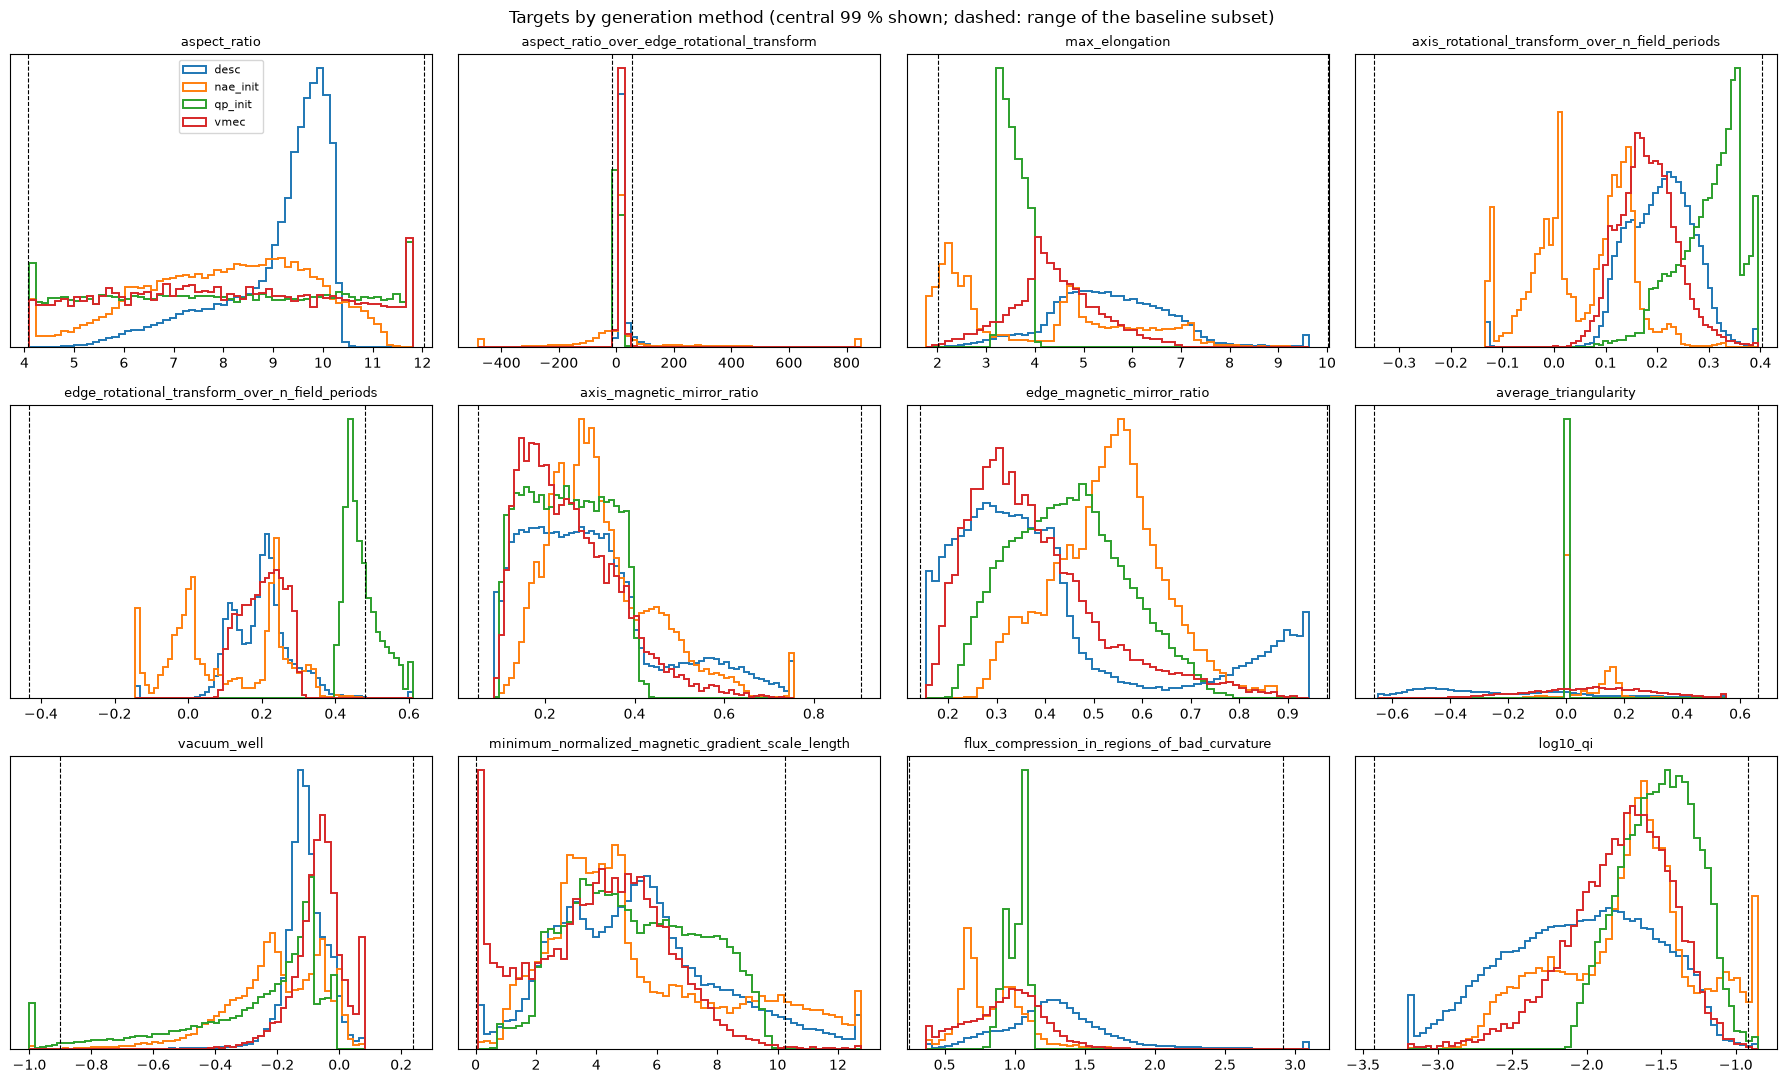

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.flat, D.TARGETS):
    lo, hi = df[col].quantile([0.005, 0.995])          # display range: central 99 %
    for method, sub in df.groupby(D.METHOD):
        ax.hist(sub[col].clip(lo, hi), bins=60, range=(lo, hi), density=True,
                histtype="step", lw=1.4, label=method)
    for x in base[col].agg(["min", "max"]):
        ax.axvline(x, color="k", ls="--", lw=0.8)
    ax.set_title(col.replace("metrics.", ""), fontsize=9)
    ax.set_yticks([])
axes.flat[0].legend(fontsize=8)
fig.suptitle("Targets by generation method (central 99 % shown; dashed: range of the baseline subset)")
fig.tight_layout()
plt.show()

Same information as numbers, on the baseline subset: these are the values the surrogate will have
to predict. The `skew` column measures asymmetry (0 = symmetric; large = long tail).

In [6]:
summary = base[D.TARGETS].describe().T[["mean", "std", "min", "50%", "max"]]
summary["skew"] = base[D.TARGETS].skew()
summary.round(4)

,mean,std,min,50%,max,skew
metrics.aspect_ratio,8.7029,1.6061,4.0763,9.1975,12.0243,-0.8933
metrics.aspect_ratio_over_edge_rotational_transform,12.8918,5.3745,-13.4311,12.0657,54.6390,1.5423
metrics.max_elongation,5.1959,1.0918,2.0093,5.1461,10.0272,0.0420
metrics.axis_rotational_transform_over_n_field_periods,0.2010,0.0666,-0.3482,0.2015,0.4033,-1.6152
metrics.edge_rotational_transform_over_n_field_periods,0.2419,0.0776,-0.4318,0.2403,0.4793,-1.4710
metrics.axis_magnetic_mirror_ratio,0.2702,0.1334,0.0499,0.2506,0.9051,1.4376
metrics.edge_magnetic_mirror_ratio,0.3839,0.1739,0.1416,0.3439,0.9813,1.5075
metrics.average_triangularity,-0.1266,0.2950,-0.6620,-0.1130,0.6610,0.1681
metrics.vacuum_well,-0.1194,0.0924,-0.9018,-0.1133,0.2367,-1.3937
metrics.minimum_normalized_magnetic_gradient_scale_length,4.7578,2.0099,0.0004,5.0781,10.2519,-0.4473


## 4. Model inputs

The inputs are the flattened Fourier coefficients `r_cos_m{m}_n{n}` and `z_sin_m{m}_n{n}`.
Some are always 0 (e.g. `z_sin` with m = 0 and n <= 0 by symmetry): they carry no information and
`D.feature_columns` drops every column that is constant over the rows given.

In [7]:
all_fourier = [c for c in df.columns if c.startswith(("r_cos_", "z_sin_"))]
features = D.feature_columns(base)
print(f"Fourier columns: {len(all_fourier)} | varying on the baseline subset: {len(features)}")
print("constant, dropped:", sorted(set(all_fourier) - set(features)))

Fourier columns: 90 | varying on the baseline subset: 81
constant, dropped: ['r_cos_m0_n-1', 'r_cos_m0_n-2', 'r_cos_m0_n-3', 'r_cos_m0_n-4', 'z_sin_m0_n-1', 'z_sin_m0_n-2', 'z_sin_m0_n-3', 'z_sin_m0_n-4', 'z_sin_m0_n0']


## 5. Out-of-distribution (OOD) splits kept for v1

The paper evaluates its surrogate on a **random** 80/20 split only (in-distribution). The splits below
are ours. Each one asks a question a stellarator designer would actually face. Codes: **RAND** random reference,
**FEAS** near-feasible designs, **INIT** initial-guess shapes, **NFP4** four field periods, **FAIL** failed physics runs.

| code | train on | test on | question |
|---|---|---|---|
| **RAND** | random 80 % of the baseline subset | the other 20 % (repeated ~20 times at training time) | what variation is "normal"? reference for every other split |
| **FEAS** | the 90 % of the baseline subset furthest from feasibility | the 10 % closest to the feasible region of the benchmark | does the surrogate warn us when an optimiser approaches the target region? (main split) |
| **INIT** | baseline subset (DESC + VMEC, NFP = 3) | QP / NAE initialisations, NFP = 3 | same machine family, shapes made by another process |
| **NFP4** | baseline subset (NFP = 3) | DESC / VMEC shapes with NFP = 4 | the shape → metrics relation changes while inputs look familiar |
| **FAIL** | models trained for RAND (no new training) | shapes for which the physics code **failed**, NFP = 3 | is the predicted uncertainty higher on shapes that would crash the real code? (detection task, AUROC; no true metrics exist) |

**Feasibility score (FEAS).** We use the benchmark's own definition (`problems.py`,
`SimpleToBuildQIStellarator.compute_feasibility`): the largest normalised constraint violation,
$\max_i \max(v_i / |t_i|, 0)$, over the 5 constraints $A \le 10$, $|\iota_{edge}|/N_{fp} \ge 0.25$,
$\log_{10} qi \le -4$, edge mirror ratio $\le 0.2$, max elongation $\le 5$. Lower = closer to feasible;
0 = feasible. No row of the dataset is feasible (best $\log_{10} qi$ in the baseline subset is about −3.4),
so any optimiser using the surrogate *must* extrapolate. FEAS is defined from targets: we check below that it
is also far in the **input** space. Thresholds 5 / 10 / 20 % are kept for a sensitivity curve.

**Dropped:** split A (aspect ratio above its 80th percentile): almost all its test shapes have $A$ between
9.9 and 10.3, i.e. a very weak extrapolation, and FEAS covers the "frontier" idea better.

**Caveats.** Test groups are cleaned like the training data (all 12 targets present) but are *not*
trimmed to the training range: being outside is the point. B only contains shapes for which the physics
code succeeded (this is the INIT split); with a 36 % failure rate for NAE, its test set is biased towards "easy" NAE shapes. In NFP4,
NFP is constant (= 3) during training, so the model cannot learn its effect: NFP4 measures how a model fails
when the relation changes, not a generalisation in NFP.

In [8]:
def feasibility(d):
    """Benchmark feasibility (SimpleToBuildQIStellarator): max of normalised constraint violations, >= 0."""
    v = np.column_stack([
        (d["metrics.aspect_ratio"] - 10.0) / 10.0,
        (0.25 - d["metrics.edge_rotational_transform_over_n_field_periods"].abs()) / 0.25,
        (d["metrics.log10_qi"] - (-4.0)) / 4.0,
        (d["metrics.edge_magnetic_mirror_ratio"] - 0.2) / 0.2,
        (d["metrics.max_elongation"] - 5.0) / 5.0,
    ])
    return pd.Series(np.maximum(v, 0).max(axis=1), index=d.index)

feas = feasibility(base)
print(f"feasible rows in the baseline subset: {(feas == 0).sum()} / {len(base)}")
print(f"best log10(qi) in the baseline subset: {base['metrics.log10_qi'].min():.2f} (benchmark bound: -4)")

rng = np.random.default_rng(42)
r_test = base.index[rng.permutation(len(base))[: int(0.2 * len(base))]]

failed = raw[raw[metric_cols].isna().all(axis=1) & (raw[D.NFP] == 3)].dropna(subset=features)

splits = {"RAND": (base.drop(r_test), base.loc[r_test])}
for q in [0.05, 0.10, 0.20]:
    cut = feas.quantile(q)
    splits[f"FEAS {q:.0%}"] = (base[feas > cut], base[feas <= cut])
splits["INIT"] = (base, df[(df[D.NFP] == 3) & ~df[D.METHOD].isin(["desc", "vmec"])])
splits["NFP4"] = (base, df[(df[D.NFP] == 4) & df[D.METHOD].isin(["desc", "vmec"])])
splits["FAIL"] = (base.drop(r_test), failed)

pd.DataFrame({name: {"train rows": len(tr), "test rows": len(te)} for name, (tr, te) in splits.items()}).T

feasible rows in the baseline subset: 0 / 26746
best log10(qi) in the baseline subset: -3.42 (benchmark bound: -4)


,train rows,test rows
RAND,21397,5349
FEAS 5%,25408,1338
FEAS 10%,24071,2675
FEAS 20%,21396,5350
INIT,26746,41141
NFP4,26746,22772
FAIL,21397,13852


### How far out are the test sets, in the input space?

For each test shape we compute the distance to its **nearest training shape**, in the space of the
81 Fourier coefficients standardised on the baseline subset (2 000 test shapes sampled per split).
The random split RAND gives the "normal" distance. A split whose distances are not larger than RAND's is
not out-of-distribution *in the inputs* (it may still be in the outputs, or in the relation, like NFP4).

Limit of this measure: it is a Euclidean distance in 81 dimensions, where all points tend to be far
from each other; it says nothing about which coefficients matter physically.

In [9]:
mu, sd = base[features].mean(), base[features].std()

def nn_distance(test, train, n=2000, seed=0):
    """Distance from up to n test shapes to their nearest training shape (standardised inputs)."""
    q = ((test[features].sample(min(n, len(test)), random_state=seed) - mu) / sd).to_numpy()
    r = ((train[features] - mu) / sd).to_numpy()
    r2 = (r**2).sum(axis=1)
    out = []
    for i in range(0, len(q), 500):
        d2 = (q[i:i + 500]**2).sum(axis=1)[:, None] + r2[None, :] - 2 * q[i:i + 500] @ r.T
        out.append(np.sqrt(np.maximum(d2.min(axis=1), 0)))
    return np.concatenate(out)

dist = {name: nn_distance(te, tr) for name, (tr, te) in splits.items()}
ref95 = np.quantile(dist["RAND"], 0.95)
pd.DataFrame({name: {"median distance": np.median(d),
                     "share beyond 95th pct of RAND": np.mean(d > ref95)}
              for name, d in dist.items()}).T.round(3)

,median distance,share beyond 95th pct of RAND
RAND,4.189,0.050
FEAS 5%,2.355,0.001
FEAS 10%,2.691,0.002
FEAS 20%,3.244,0.014
INIT,4.042,0.024
NFP4,5.903,0.034
FAIL,7.037,0.229


Distributions of two targets in each test set, against the training set of RAND. FAIL has no targets
(the physics code failed), so it is absent here.

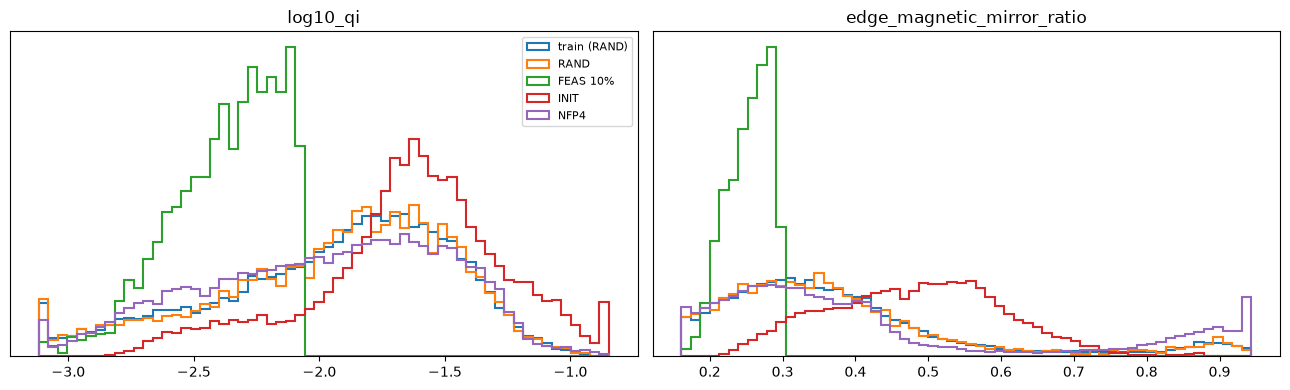

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
show = {k: v for k, v in splits.items() if k in ["RAND", "FEAS 10%", "INIT", "NFP4"]}
for ax, col in zip(axes, ["metrics.log10_qi", "metrics.edge_magnetic_mirror_ratio"]):
    sets = {"train (RAND)": show["RAND"][0]} | {name: te for name, (_, te) in show.items()}
    lo, hi = pd.concat(sets.values())[col].quantile([0.005, 0.995])
    for name, s in sets.items():
        ax.hist(s[col].clip(lo, hi), bins=60, range=(lo, hi), density=True, histtype="step", lw=1.5, label=name)
    ax.set_title(col.replace("metrics.", ""))
    ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Summary

1. **Methods × NFP.** 158,685 configurations with metrics: DESC 87,727, NAE 31,287, QP 29,551,
   VMEC 10,120. NFP = 3 dominates for every method except DESC; VMEC has only 150–240 rows outside NFP = 3,
   too few for a reliable test set.
2. **Physics-code failures.** Metrics are missing all-or-nothing (rows have either 12 or 0 metrics).
   Failure rate: NAE 36.0 %, VMEC 35.8 %, QP 1.1 %, DESC ~0 % (one empty row). The surrogate is only trained
   on shapes for which the physics code converged.
3. **Paper baseline subset.** 158,685 → 68,191 (NFP = 3) → 27,050 (DESC or VMEC) → **26,746** after trimming
   0.05 % tails per target (26,897 with 0.025 % per end). The paper reports ~23k points; the gap already
   exists before trimming and its cause is unknown.
4. **Targets.** No target is missing after cleaning. Methods cover very different ranges: e.g. DESC
   aspect ratios pile up between 9 and 10.3, QP and VMEC spread evenly between 4 and 12.
   `aspect_ratio_over_edge_rotational_transform` has extreme values where $\iota_{edge}\approx 0$.
5. **Inputs.** 90 flattened Fourier columns, 81 vary on the baseline subset; the 9 constant ones are the
   $m = 0,\ n \le 0$ modes fixed by symmetry.
6. **OOD splits.** No baseline shape satisfies all benchmark constraints (best $\log_{10} qi$ = −3.42 vs −4).
   Nearest-neighbour distance of test shapes to the training set, compared with the random reference RAND
   (median 4.19): FEAS 10 % = 2.69 (closer than random: an *output* shift, extreme metrics on familiar shapes),
   INIT = 4.04 (same as random in the inputs, different metrics), NFP4 = 5.90 (the input–output relation
   changes), FAIL = 7.04 with 23 % of its shapes beyond the 95th percentile of RAND (the only clear
   *input* shift).